# Birth Rate Analysis: does the calendar steer when babies are born?

**The question:** the U.S. recorded about 152 million births between 1969 and 2008. Do babies arrive evenly across the week and the year, or does the calendar leave fingerprints on the data? And if it does, how well can we *forecast* a day's births?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data (it has two very different halves)
4. Hypotheses and why we chose each test
5. H1: the weekend dip
6. H2: the seasons
7. H3: holidays, Friday the 13th and leap day
8. H4: boys and girls
9. Forecasting honestly
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab ML/birth-rate-analysis/birth_rate_analysis.ipynb`, or *Run All* in any Jupyter. The data downloads itself on the first run.

## 1. 💡 The simple analogy

Imagine a **bakery**. Some customers wander in whenever they like: those are the cakes nobody planned. But many cakes are **pre-ordered**, and pre-orders only get picked up when the shop is open: on weekdays, not on Sunday, not on Christmas.

Hospitals work a bit like that. Many babies arrive *on their own schedule* (nature), but a growing share of births are **scheduled** (induced labour, planned C-sections), and scheduled births follow the **business calendar**. If that is true, the data should show:

- fewer births on **weekends** and **holidays** (the shop is closed), and
- the weekend gap should **grow** over the years as scheduling becomes more common.

We will test those ideas with real statistics instead of just eyeballing a chart.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every bootstrap and every model fit comes out the same each time you run it.

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from statsmodels.stats.multitest import multipletests

DATA_URL = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
DATA_PATH = Path("data/births.csv")
OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 5_000
TEST_YEARS = range(1984, 1989)
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the raw file and check what is actually in it. *Why:* before testing anything, we need to know whether each row means what we think it means. This dataset (U.S. births counted by the CDC's National Center for Health Statistics, republished by Jake VanderPlas) has a surprise.

In [2]:
def load_births(path: Path = DATA_PATH) -> pd.DataFrame:
    """Loads the raw births file, downloading it on first use.

    Args:
        path: Where to cache the raw file.

    Returns:
        Raw DataFrame with year, month, day, gender and births columns.

    Raises:
        ValueError: If the file does not have the expected shape.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    raw = pd.read_csv(path)
    if raw.shape != (15547, 5):
        raise ValueError(f"Unexpected data: shape={raw.shape}")
    return raw


raw = load_births()
raw.head()

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


In [3]:
has_day = raw["day"].notna()
dates = pd.to_datetime(raw.loc[has_day, ["year", "month", "day"]].astype(int), errors="coerce")
valid_daily = has_day & dates.reindex(raw.index).notna()
bad_date = has_day & ~valid_daily
monthly_era = ~has_day

audit = pd.DataFrame(
    {
        "rows": [valid_daily.sum(), bad_date.sum(), monthly_era.sum()],
        "births": [raw.loc[m, "births"].sum() for m in (valid_daily, bad_date, monthly_era)],
        "years": [
            f"{raw.loc[m, 'year'].min()}-{raw.loc[m, 'year'].max()}"
            for m in (valid_daily, bad_date, monthly_era)
        ],
    },
    index=["Daily, valid date", "Daily, impossible date", "Monthly total (day missing)"],
)
display(audit)
print(f"Impossible-date rows hold {audit.loc['Daily, impossible date', 'births']:,} births "
      f"({audit.loc['Daily, impossible date', 'births'] / raw.loc[has_day, 'births'].sum():.3%} "
      "of the daily era).")
print("Examples of impossible dates:",
      raw.loc[bad_date, ["year", "month", "day"]].drop_duplicates().head(4).to_dict("records"))

,rows,births,years
"Daily, valid date",14610,70485508,1969-1988
"Daily, impossible date",457,7433,1969-1988
Monthly total (day missing),480,81281437,1989-2008


Impossible-date rows hold 7,433 births (0.011% of the daily era).
Examples of impossible dates: [{'year': 1969, 'month': 1, 'day': 99.0}, {'year': 1969, 'month': 2, 'day': 29.0}, {'year': 1969, 'month': 2, 'day': 30.0}, {'year': 1969, 'month': 2, 'day': 31.0}]


**How to read this.** The file is really **two datasets glued together**:

- **1969 to 1988: daily rows.** Each row is one day and one sex, with a real count. Almost all of them have valid dates.
- **1989 to 2008: monthly totals.** The `day` column is *empty* and each row holds a **whole month's** births for one sex (that is why the counts are around 170,000 instead of about 5,000).
- A small number of daily rows (457 rows, about 0.01% of the births) carry **impossible dates** like day 99 or February 30. They are probably births with an unknown or mistyped day.

> **A trap in the legacy notebook this replaces.** It filled the missing days with `0`, which turned the monthly totals into fake "day 0" rows, then relied on an outlier filter to throw them away by accident. It also called `pd.datetime`, which no longer exists in modern pandas. We handle each era on purpose instead:
>
> - **Daily questions** (weekdays, holidays, forecasting) use only the 7,305 valid days of 1969-1988.
> - **Monthly questions** (seasons, long-term trend, sex ratio) use all 40 years, because a month total is a month total whatever era it came from. Even the impossible-date rows keep a valid month, so their births count towards the monthly totals.

In [4]:
def build_daily(raw: pd.DataFrame) -> pd.Series:
    """Builds the total births per calendar day for the daily era.

    Args:
        raw: Raw births table.

    Returns:
        Series indexed by date with both sexes summed.

    Raises:
        ValueError: If a calendar day is missing.
    """
    rows = raw.dropna(subset=["day"])
    when = pd.to_datetime(rows[["year", "month", "day"]].astype(int), errors="coerce")
    daily = rows.assign(date=when).dropna(subset=["date"]).groupby("date")["births"].sum()
    daily = daily.asfreq("D")
    if daily.isna().any():
        raise ValueError("Calendar gaps in the daily era")
    return daily


def build_monthly(raw: pd.DataFrame) -> pd.DataFrame:
    """Builds monthly births for all 40 years, with a per-day rate and a yearly index.

    Args:
        raw: Raw births table.

    Returns:
        One row per year and month: births, days, births per day, and ``rel``
        (births per day relative to that year's average, so 1.05 means 5% above).
    """
    monthly = raw.groupby(["year", "month"], as_index=False)["births"].sum()
    first_of_month = pd.to_datetime(monthly.assign(day=1)[["year", "month", "day"]])
    monthly["days"] = first_of_month.dt.days_in_month
    monthly["per_day"] = monthly["births"] / monthly["days"]
    monthly["rel"] = monthly["per_day"] / monthly.groupby("year")["per_day"].transform("mean")
    return monthly


daily = build_daily(raw)
monthly = build_monthly(raw)
print(f"Daily series: {len(daily):,} days, {daily.index.min():%Y-%m-%d} to "
      f"{daily.index.max():%Y-%m-%d}, mean {daily.mean():,.0f} births/day")
print(f"Monthly table: {len(monthly)} months, {monthly['year'].min()} to {monthly['year'].max()}")

Daily series: 7,305 days, 1969-01-01 to 1988-12-31, mean 9,649 births/day
Monthly table: 480 months, 1969 to 2008


### The big picture: births per year

*What:* total births per year, with the daily-data era shaded. *Why:* a long-run view tells us whether "the level of births" is stable, which matters a lot later when we try to forecast.

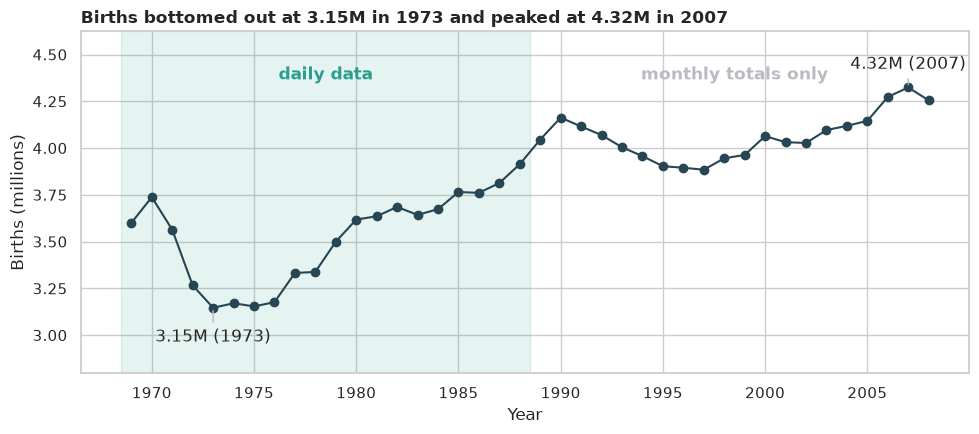

In [5]:
annual = monthly.groupby("year")["births"].sum() / 1e6
low_year, high_year = annual.idxmin(), annual.idxmax()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(1968.5, 1988.5, color=TEAL, alpha=0.12)
ax.text(1978.5, annual.max() * 1.01, "daily data", ha="center", color=TEAL, fontweight="bold")
ax.text(1998.5, annual.max() * 1.01, "monthly totals only", ha="center", color=GREY,
        fontweight="bold")
ax.plot(annual.index, annual.values, marker="o", color=NAVY)
for year, offset in ((low_year, -0.18), (high_year, 0.1)):
    ax.annotate(f"{annual[year]:.2f}M ({year})", (year, annual[year]),
                (year, annual[year] + offset), ha="center",
                arrowprops={"arrowstyle": "-", "color": GREY})
ax.set_ylim(annual.min() - 0.35, annual.max() + 0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Births (millions)")
ax.set_title(f"Births bottomed out at {annual.min():.2f}M in {low_year} and peaked at "
             f"{annual.max():.2f}M in {high_year}", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_annual_births.png", dpi=150)
plt.show()

**How to read this.** Births dipped through the early 1970s to a low of about 3.15 million (1973), then climbed steadily to about 4.3 million in the 2000s, with the climb continuing past the end of the daily data. The level of births **wanders from year to year** by a percent or two, which is going to set a limit on how well any forecast can do.

## 4. 🔬 Hypotheses and why we chose each test

Here are our questions, each with its null (H₀, "nothing special is going on") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Test |
|---|---|---|---|---|
| H1 | Are weekends quieter than weekdays, and is the gap growing? | Weekend and weekday births are equal; the gap doesn't change over time | Weekends are lower; the gap trends over the years | Paired Wilcoxon signed-rank on 1,042 weeks; Spearman and a regression slope on 20 yearly ratios |
| H2 | Do births depend on the month? | Births per day are the same in every month | At least one month differs | Kruskal-Wallis with ε² (40 years × 12 months) |
| H3 | Are holidays, Friday the 13th and leap day unusual? | A special day is typical for its weekday and season | It is higher or lower than usual | Wilcoxon signed-rank vs a local baseline, Holm-corrected over 10 days |
| H4 | Do boys and girls arrive 50/50? Is the split stable? | P(boy) = 0.5; the share is the same in every decade | Differs | z-test with a Wilson CI; chi-square across decades with Cramér's V |

**Why non-parametric and paired tests?** Births counts are not bell-shaped around a single average because trend, season and weekday all push them around. **Paired** tests compare things that share the same conditions (the weekend and weekdays of the *same week*), which removes the slow drift of the long-run level. Rank-based tests (Wilcoxon, Kruskal-Wallis) work on the *order* of the values, so a few odd days can't hijack them.

**Why Holm correction?** Test enough special days and one will look unusual by pure luck, like buying extra lottery tickets. Holm adjusts the p-values so the chance of *any* false alarm across all ten stays at 5%.

**Why report effect sizes and CIs?** With millions of births, *every* difference becomes "statistically significant". A p-value only says "unlikely to be luck"; the **effect size** says whether it matters, and a **confidence interval** says how precisely we know it.

## 5. H1: the weekend dip

### 5a. Paired comparison within each week

*What:* for every full Monday-to-Sunday week, compare the **average weekend day** (Sat, Sun) to the **average weekday** (Mon to Fri) of that same week, as a ratio. *Why paired and why ratios?* Comparing a Saturday in 1970 to a Wednesday in 1987 would mix in 17 years of trend. Staying within one week holds season and long-run level fixed, and a ratio (0.85 means "15% fewer") is easy to read.

**The test.** The Wilcoxon signed-rank test looks at the 1,042 weekly differences (on a log scale, so ratios are symmetric around 0). **H₀:** the median log ratio is 0 (weekends equal weekdays). We add a **bootstrap 95% CI** for the median ratio by re-drawing weeks with replacement 5,000 times.

In [6]:
def weekly_weekend_ratio(daily: pd.Series) -> pd.Series:
    """Computes the weekend/weekday births ratio for every complete Mon-Sun week.

    Args:
        daily: Births per day with a daily DatetimeIndex.

    Returns:
        Series indexed by week with the ratio of mean weekend to mean weekday births.
    """
    frame = daily.to_frame("births")
    frame["week"] = frame.index.to_period("W-SUN")
    frame["weekend"] = frame.index.dayofweek >= 5
    complete = frame.groupby("week")["births"].transform("size") == 7
    means = frame[complete].groupby(["week", "weekend"])["births"].mean().unstack()
    return means[True] / means[False]


def bootstrap_median_ci(values: np.ndarray, seed: int = SEED) -> tuple[float, float]:
    """Bootstraps a 95% confidence interval for the median.

    Args:
        values: Sample values.
        seed: Seed for the random generator.

    Returns:
        CI lower bound, CI upper bound.
    """
    rng = np.random.default_rng(seed)
    medians = np.median(rng.choice(values, (N_BOOTSTRAP, len(values))), axis=1)
    lo, hi = np.percentile(medians, [2.5, 97.5])
    return float(lo), float(hi)


weekly = weekly_weekend_ratio(daily)
log_ratio = np.log(weekly)
wilcoxon = stats.wilcoxon(log_ratio)
lo, hi = bootstrap_median_ci(weekly.to_numpy())
print(f"Complete weeks: {len(weekly):,}")
print(f"Median weekend/weekday ratio: {weekly.median():.3f}  (95% CI {lo:.3f} to {hi:.3f})")
print(f"Weeks where the weekend was lower: {(weekly < 1).mean():.1%}")
print(f"Wilcoxon signed-rank p = {fmt_p(wilcoxon.pvalue)}")

Complete weeks: 1,042
Median weekend/weekday ratio: 0.845  (95% CI 0.843 to 0.847)
Weeks where the weekend was lower: 100.0%
Wilcoxon signed-rank p = 4.7e-172


**How to read this.** Across **1,042 complete weeks**, the typical weekend day had **84.5% of a weekday's births** (95% CI 84.3% to 84.7%), about **15% fewer**. The weekend was lower in **every single week** (100%). The p-value is astronomically small (about 5e-172), so we **reject H₀**. The CI is very narrow because we have over a thousand weeks of evidence.

### 5b. Which days are busy? And is the gap growing?

*What:* first, the average births per weekday relative to that year's overall average (so 1.05 means 5% above a typical day). Second, for each of the 20 years, the weekend/weekday ratio, to see whether it changes. *Why:* the bakery idea predicts a **growing** weekend dip as scheduled births become more common. **H₀:** the yearly ratio has no trend (Spearman ρ = 0, regression slope = 0). We use Spearman because it only needs the ordering of the points, and a regression slope with a 95% CI to say *how fast* it changes.

In [7]:
frame = daily.to_frame("births")
frame["year"] = frame.index.year
frame["dow"] = frame.index.dayofweek
frame["rel"] = frame["births"] / frame.groupby("year")["births"].transform("mean")

by_dow = frame.groupby("dow")["rel"].agg(["mean", "sem", "count"])
by_dow["ci"] = stats.t.ppf(0.975, by_dow["count"] - 1) * by_dow["sem"]

yearly_ratio = frame.groupby("year").apply(
    lambda g: g.loc[g["dow"] >= 5, "births"].mean() / g.loc[g["dow"] < 5, "births"].mean(),
    include_groups=False,
)
spearman = stats.spearmanr(yearly_ratio.index, yearly_ratio.to_numpy())
fit = stats.linregress(yearly_ratio.index, yearly_ratio.to_numpy())
slope_ci = stats.t.ppf(0.975, len(yearly_ratio) - 2) * fit.stderr

print("Relative births by weekday (1.00 = that year's average day):")
print(by_dow["mean"].round(3).rename(dict(enumerate(DOW_NAMES))).to_string())
print(f"\nWeekend/weekday ratio: {yearly_ratio.iloc[0]:.3f} in {yearly_ratio.index[0]}, "
      f"{yearly_ratio.iloc[-1]:.3f} in {yearly_ratio.index[-1]}")
print(f"Spearman rho = {spearman.statistic:+.2f}, p = {fmt_p(spearman.pvalue)}")
print(f"Slope = {fit.slope:+.4f} per year (95% CI {fit.slope - slope_ci:+.4f} "
      f"to {fit.slope + slope_ci:+.4f})")

Relative births by weekday (1.00 = that year's average day):
dow
Mon    1.030
Tue    1.074
Wed    1.045
Thu    1.035
Fri    1.051
Sat    0.904
Sun    0.860

Weekend/weekday ratio: 0.881 in 1969, 0.790 in 1988
Spearman rho = -0.98, p = 2.4e-13
Slope = -0.0044 per year (95% CI -0.0051 to -0.0037)


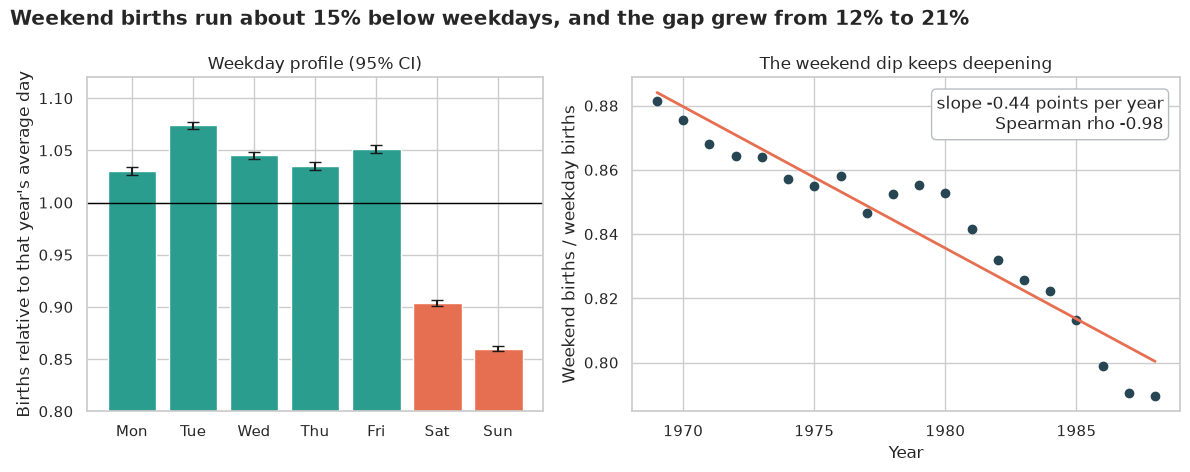

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})

colors = [TEAL] * 5 + [ORANGE] * 2
axes[0].bar(DOW_NAMES, by_dow["mean"], yerr=by_dow["ci"], color=colors, capsize=4)
axes[0].axhline(1, color="black", lw=1)
axes[0].set_ylim(0.8, 1.12)
axes[0].set_ylabel("Births relative to that year's average day")
axes[0].set_title("Weekday profile (95% CI)")

years = yearly_ratio.index.to_numpy()
axes[1].plot(years, yearly_ratio.to_numpy(), "o", color=NAVY)
axes[1].plot(years, fit.intercept + fit.slope * years, color=ORANGE, lw=2)
axes[1].set_xlabel("Year")
axes[1].set_xticks(range(1970, 1990, 5))
axes[1].set_ylabel("Weekend births / weekday births")
axes[1].text(0.97, 0.95,
             f"slope {fit.slope * 100:+.2f} points per year\n"
             f"Spearman rho {spearman.statistic:+.2f}",
             transform=axes[1].transAxes, ha="right", va="top",
             bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
axes[1].set_title("The weekend dip keeps deepening")

fig.suptitle(f"Weekend births run about {1 - weekly.median():.0%} below weekdays, "
             f"and the gap grew from {1 - yearly_ratio.iloc[0]:.0%} to "
             f"{1 - yearly_ratio.iloc[-1]:.0%}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_weekday_profile_and_trend.png", dpi=150)
plt.show()

**How to read this.**

- **Left:** Tuesday is the busiest day (about 7% above average) and **Sunday the quietest (about 14% below)**. Saturday is about 10% below. The five weekdays are within a few percent of each other.
- **Right:** the weekend/weekday ratio falls almost in a straight line, from **0.88 in 1969 to 0.79 in 1988**: the weekend gap went from about 12% to about 21%.
- **Test:** Spearman ρ ≈ −0.98 (p ≈ 2e-13) and a slope of about **−0.0044 per year** (95% CI roughly −0.0051 to −0.0037). The CI excludes 0, so we **reject H₀**: the weekend dip is *deepening* by about 0.44 percentage points every year, exactly what the "scheduled births" idea predicts.

> **Careful:** this shows the *pattern* fits the bakery idea; it does not prove the cause. The data has no field saying which births were induced or planned. The explanation is a hypothesis that fits, not something we measured.

## 6. H2: the seasons

*What:* use all 40 years of monthly data. Months have different lengths, so we first convert each month to **births per day**, then divide by that year's average so a "1.05" means 5% above a typical day that year (this removes the long-run trend). *Why Kruskal-Wallis?* It's the rank-based version of one-way ANOVA: it compares 12 groups (months) without assuming bell shapes. **H₀:** the 12 months have the same distribution of relative births per day. **Hₐ:** at least one month differs. Its effect size is **ε²** (about 0.01 small, 0.06 medium, 0.14 large). Because "some month differs" is not very specific, we also compare the highest and lowest months head-to-head with Mann-Whitney and **Cliff's δ**, which is *P(the first month's value is higher) minus P(it is lower)*, running from −1 to +1.

In [9]:
month_groups = [monthly.loc[monthly["month"] == m, "rel"].to_numpy() for m in range(1, 13)]
H, p_kw = stats.kruskal(*month_groups)
epsilon_sq = (H - 12 + 1) / (len(monthly) - 12)

month_stats = monthly.groupby("month")["rel"].agg(["mean", "sem", "count"])
month_stats["ci"] = stats.t.ppf(0.975, month_stats["count"] - 1) * month_stats["sem"]
top, bottom = month_stats["mean"].idxmax(), month_stats["mean"].idxmin()
mwu = stats.mannwhitneyu(month_groups[top - 1], month_groups[bottom - 1])
cliffs_delta = 2 * mwu.statistic / (len(month_groups[top - 1]) * len(month_groups[bottom - 1])) - 1

print(f"Kruskal-Wallis: H = {H:.1f}, p = {fmt_p(p_kw)}, epsilon^2 = {epsilon_sq:.2f}")
print(f"Highest month: {MONTH_NAMES[top - 1]} ({month_stats.loc[top, 'mean'] - 1:+.1%}), "
      f"lowest: {MONTH_NAMES[bottom - 1]} ({month_stats.loc[bottom, 'mean'] - 1:+.1%})")
print(f"{MONTH_NAMES[top - 1]} vs {MONTH_NAMES[bottom - 1]}: Mann-Whitney p = {fmt_p(mwu.pvalue)}, "
      f"Cliff's delta = {cliffs_delta:+.2f}")
(month_stats["mean"].round(3).rename(dict(enumerate(MONTH_NAMES, start=1))).to_frame("relative").T)

Kruskal-Wallis: H = 349.0, p = 3.9e-68, epsilon^2 = 0.72
Highest month: Sep (+6.4%), lowest: Jan (-4.0%)
Sep vs Jan: Mann-Whitney p = 1.4e-14, Cliff's delta = +1.00


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
relative,0.96,0.983,0.984,0.969,0.979,1.003,1.038,1.051,1.064,1.006,0.979,0.983


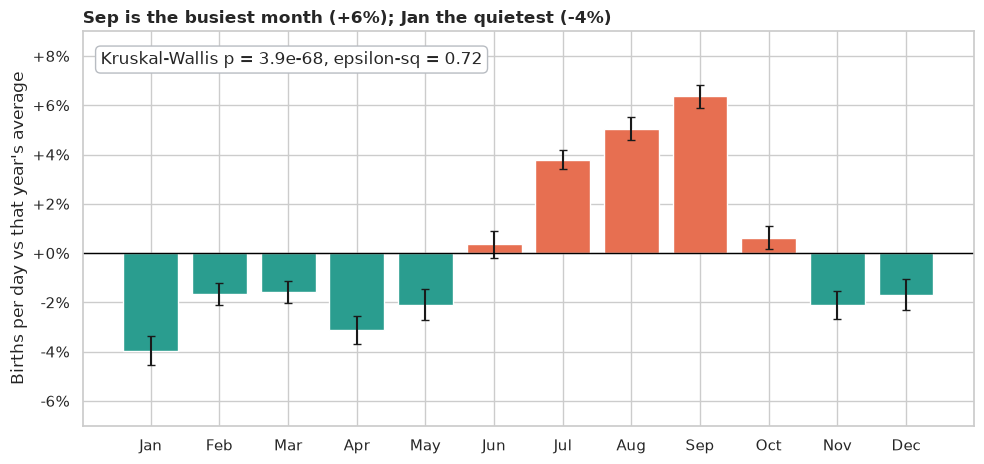

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
bar_colors = np.where(month_stats["mean"] >= 1, ORANGE, TEAL)
ax.bar(MONTH_NAMES, month_stats["mean"] - 1, yerr=month_stats["ci"], bottom=1,
       color=bar_colors, capsize=3)
ax.axhline(1, color="black", lw=1)
ax.set_ylim(0.93, 1.09)
ax.yaxis.set_major_formatter(lambda v, _: f"{v - 1:+.0%}")
ax.set_ylabel("Births per day vs that year's average")
ax.text(0.02, 0.95, f"Kruskal-Wallis p = {fmt_p(p_kw)}, epsilon-sq = {epsilon_sq:.2f}",
        transform=ax.transAxes, va="top", bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
ax.set_title(f"{MONTH_NAMES[top - 1]} is the busiest month "
             f"({month_stats.loc[top, 'mean'] - 1:+.0%}); {MONTH_NAMES[bottom - 1]} the quietest "
             f"({month_stats.loc[bottom, 'mean'] - 1:+.0%})", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_monthly_seasonality.png", dpi=150)
plt.show()

**How to read this.** There is a clear **summer-to-early-autumn peak**: July (+4%), August (+5%) and **September (+6%, the busiest)**, while **January is the quietest (−4%)**. Kruskal-Wallis gives H ≈ 349 and p ≈ 4e-68 with **ε² ≈ 0.72, a very large effect** (far above the 0.14 "large" threshold), so we **reject H₀**: the month clearly matters. Head to head, September beats January in essentially every year (Cliff's δ close to +1). The whiskers (95% CIs, each from 40 years) are short compared with the gaps between months, which is why the seasonal pattern is so clear.

Notice what the test does *not* tell us: **why**. Nine months before a September birth is December, which fits with winter-holiday conceptions, but conception timing is not in this data.

## 7. H3: holidays, Friday the 13th and leap day

### How do we decide a day is "unusual"?

*What:* a Tuesday in July is always busier than a Sunday in January, so we can't just compare a holiday to the yearly average. Instead, for each special day we build a **local baseline**: the **median births on the same weekday in the three weeks before and the three weeks after** (six comparison days). Then we compute the **log of births ÷ baseline**, where 0 means "perfectly typical" and −0.15 means about 14% below. *Why the median?* If one of the six comparison days is itself a holiday (for example, New Year's Day is one week after Christmas), the median ignores that outlier. *Why logs?* They make "10% above" and "10% below" symmetric.

**Test:** for each special day we have one observation per year (20 years, except leap day with 5 and Friday the 13th with 34). The **Wilcoxon signed-rank test** asks **H₀:** the median log ratio is 0. We add a bootstrap 95% CI and apply **Holm correction across all 10 special days**.

In [11]:
def nth_weekday(year: int, month: int, weekday: int, n: int) -> pd.Timestamp:
    """Finds the n-th given weekday of a month (n=-1 means the last one).

    Args:
        year: Calendar year.
        month: Calendar month, 1 to 12.
        weekday: Monday=0 ... Sunday=6.
        n: Which occurrence, counting from 1; -1 for the last.

    Returns:
        The matching date.
    """
    days = pd.date_range(f"{year}-{month:02d}-01", periods=31, freq="D")
    days = days[(days.month == month) & (days.dayofweek == weekday)]
    return days[n - 1] if n > 0 else days[-1]


def special_days(years: range, all_days: pd.DatetimeIndex) -> dict[str, list[pd.Timestamp]]:
    """Lists the dates of each special day we want to test.

    Args:
        years: Years to include.
        all_days: Every date available in the daily series.

    Returns:
        Special-day name mapped to its dates.
    """
    return {
        "New Year's Day": [pd.Timestamp(y, 1, 1) for y in years],
        "Memorial Day": [nth_weekday(y, 5, 0, -1) for y in years],
        "July 4": [pd.Timestamp(y, 7, 4) for y in years],
        "Labor Day": [nth_weekday(y, 9, 0, 1) for y in years],
        "Halloween": [pd.Timestamp(y, 10, 31) for y in years],
        "Thanksgiving": [nth_weekday(y, 11, 3, 4) for y in years],
        "Christmas Eve": [pd.Timestamp(y, 12, 24) for y in years],
        "Christmas Day": [pd.Timestamp(y, 12, 25) for y in years],
        "Leap day (Feb 29)": [pd.Timestamp(y, 2, 29) for y in years if y % 4 == 0],
        "Friday the 13th": [d for d in all_days if d.day == 13 and d.dayofweek == 4],
    }


def local_baseline(daily: pd.Series, weeks: tuple[int, ...] = (-3, -2, -1, 1, 2, 3)) -> pd.Series:
    """Median births on the same weekday in the surrounding weeks.

    Args:
        daily: Births per day.
        weeks: Week offsets to compare against.

    Returns:
        Baseline value for every day (NaN near the ends of the series).
    """
    shifted = pd.concat([daily.shift(7 * w) for w in weeks], axis=1)
    return shifted.median(axis=1)


baseline = local_baseline(daily)
log_vs_baseline = np.log(daily / baseline)
specials = special_days(range(1969, 1989), daily.index)

rows = {}
for name, days in specials.items():
    sample = log_vs_baseline.loc[days].dropna().to_numpy()
    lo, hi = bootstrap_median_ci(sample)
    rows[name] = {
        "n": len(sample),
        "pct_vs_usual": 100 * (np.exp(np.median(sample)) - 1),
        "ci_low": 100 * (np.exp(lo) - 1),
        "ci_high": 100 * (np.exp(hi) - 1),
        "p": stats.wilcoxon(sample).pvalue,
    }
holidays = pd.DataFrame(rows).T
holidays["n"] = holidays["n"].astype(int)
holidays["p_holm"] = multipletests(holidays["p"], method="holm")[1]
holidays = holidays.sort_values("pct_vs_usual")
holidays.style.format({"pct_vs_usual": "{:+.1f}%", "ci_low": "{:+.1f}%", "ci_high": "{:+.1f}%",
                       "p": "{:.1e}", "p_holm": "{:.1e}"})

,n,pct_vs_usual,ci_low,ci_high,p,p_holm
Christmas Day,20,-19.9%,-21.8%,-15.8%,1.9e-06,1.7e-05
Thanksgiving,20,-19.1%,-21.7%,-18.7%,1.9e-06,1.7e-05
Labor Day,20,-17.3%,-18.0%,-16.2%,1.9e-06,1.7e-05
New Year's Day,20,-16.8%,-18.3%,-14.4%,5.7e-06,2.9e-05
Memorial Day,20,-14.2%,-16.4%,-13.0%,9.5e-06,3.8e-05
July 4,20,-14.2%,-15.0%,-8.2%,1.9e-05,5.7e-05
Christmas Eve,20,-13.9%,-17.3%,-12.8%,1.9e-06,1.7e-05
Leap day (Feb 29),5,-5.0%,-7.4%,+3.1%,1.9e-01,1.9e-01
Friday the 13th,34,-2.8%,-3.9%,-1.5%,2.8e-07,2.8e-06
Halloween,20,-2.5%,-4.7%,-1.3%,3.7e-03,7.3e-03


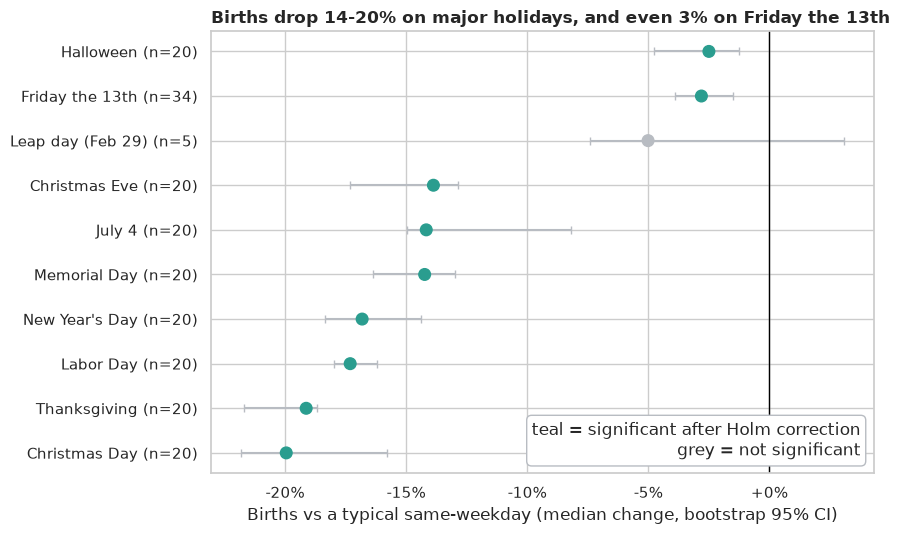

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ypos = np.arange(len(holidays))
significant = holidays["p_holm"] < 0.05
ax.errorbar(holidays["pct_vs_usual"], ypos,
            xerr=[holidays["pct_vs_usual"] - holidays["ci_low"],
                  holidays["ci_high"] - holidays["pct_vs_usual"]],
            fmt="none", ecolor=GREY, capsize=3)
ax.scatter(holidays["pct_vs_usual"], ypos, c=np.where(significant, TEAL, GREY), s=70, zorder=3)
ax.axvline(0, color="black", lw=1)
labels = [f"{name} (n={n})" for name, n in zip(holidays.index, holidays["n"], strict=True)]
ax.set_yticks(ypos, labels)
ax.set_xlabel("Births vs a typical same-weekday (median change, bootstrap 95% CI)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.text(0.98, 0.04, "teal = significant after Holm correction\ngrey = not significant",
        transform=ax.transAxes, ha="right", bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
ax.set_title("Births drop 14-20% on major holidays, and even 3% on Friday the 13th",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_special_days.png", dpi=150)
plt.show()

**How to read this.**

- **Major holidays: reject H₀ for all eight.** Births fall by roughly **14% to 20%** compared with a typical same weekday: Christmas Day (about −20%), Thanksgiving (−19%), Labor Day and New Year's Day (−17%), Memorial Day, July 4 and Christmas Eve (−14%). The bootstrap CIs sit well below 0. This is the bakery idea again: scheduled births avoid days when the hospital runs on a skeleton crew.
- **Halloween: a small but real dip** (about −2.5%, CI roughly −4.7% to −1.3%, Holm p ≈ 0.007). It's tiny next to the major holidays, and we shouldn't invent a story for it.
- **Friday the 13th: about −2.8%** (CI roughly −3.9% to −1.5%) across 34 occurrences. That's a statistically clear but *small* effect, consistent with scheduled procedures being moved off a date some people consider unlucky. Compare that with Christmas: the superstition is real in the data, but it is about a seventh of a holiday's effect.
- **Leap day: fail to reject H₀.** Births on Feb 29 are about 5% below usual but with a CI from about −7% to +3% and p ≈ 0.19. The catch: there are only **5 leap days** in the daily era, and with n = 5 the Wilcoxon test can't even reach p below about 0.06, however large the effect. So this is "not enough data to say", not "leap-day babies are ordinary".

## 8. H4: boys and girls

*What:* roughly how many boys are born compared to girls, and has that changed? **First question:** is the male share different from 50%? With about 152 million births, a **z-test** for a proportion is appropriate (a normal approximation is excellent at this size), and a **Wilson interval** is a well-behaved 95% CI for the share. **H₀:** P(boy) = 0.5. **Second question:** is the share the same in every decade? The **chi-square test of homogeneity** compares the boy/girl split across decades, and **Cramér's V** (0 = no association, 1 = perfect) measures how big the difference is. **Third:** a regression slope of male share against year.

> **The lesson to look for.** When the sample is enormous, *everything* is "statistically significant", so the p-value stops being informative and the **effect size** is what tells you whether the result matters.

In [13]:
by_sex = raw.groupby("gender")["births"].sum()
n_total, n_male = by_sex.sum(), by_sex["M"]
male_share = n_male / n_total

z = (male_share - 0.5) / np.sqrt(0.25 / n_total)
p_z = 2 * stats.norm.sf(abs(z))
wilson_half = 1.96 * np.sqrt(male_share * (1 - male_share) / n_total)  # Wilson ~ Wald at this n

print(f"Total births: {n_total:,}")
p_text = "p < 1e-300" if p_z == 0 else f"p = {p_z:.1e}"
print(f"Male share: {male_share:.4%} (95% CI +/- {wilson_half:.4%}); z = {z:.0f}, {p_text}")
print(f"About {male_share / (1 - male_share) * 100:.0f} boys for every 100 girls")

by_decade = raw.assign(decade=10 * (raw["year"] // 10)).pivot_table(
    "births", index="decade", columns="gender", aggfunc="sum"
)
chi2, p_chi, dof, _ = stats.chi2_contingency(by_decade.to_numpy())
cramers_v = np.sqrt(chi2 / by_decade.to_numpy().sum())
print(f"\nChi-square across decades: chi2({dof}) = {chi2:.0f}, p = {fmt_p(p_chi)}, "
      f"Cramer's V = {cramers_v:.4f}")

yearly = raw.groupby(["year", "gender"])["births"].sum().unstack()
share_by_year = yearly["M"] / (yearly["M"] + yearly["F"])
share_fit = stats.linregress(share_by_year.index, share_by_year.to_numpy())
share_ci = stats.t.ppf(0.975, len(share_by_year) - 2) * share_fit.stderr
change = share_fit.slope * (share_by_year.index.max() - share_by_year.index.min())
print(f"Male share in {share_by_year.index[0]}: {share_by_year.iloc[0]:.3%}; "
      f"in {share_by_year.index[-1]}: {share_by_year.iloc[-1]:.3%}")
slope_lo, slope_hi = (share_fit.slope - share_ci) * 100, (share_fit.slope + share_ci) * 100
print(f"Slope = {share_fit.slope * 100:+.4f} percentage points per year "
      f"(95% CI {slope_lo:+.4f} to {slope_hi:+.4f}); "
      f"fitted change over the period: {change * 100:+.2f} points")

Total births: 151,774,378
Male share: 51.2198% (95% CI +/- 0.0080%); z = 301, p < 1e-300
About 105 boys for every 100 girls

Chi-square across decades: chi2(4) = 130, p = 4.7e-27, Cramer's V = 0.0009
Male share in 1969: 51.291%; in 2008: 51.167%
Slope = -0.0039 percentage points per year (95% CI -0.0048 to -0.0031); fitted change over the period: -0.15 points


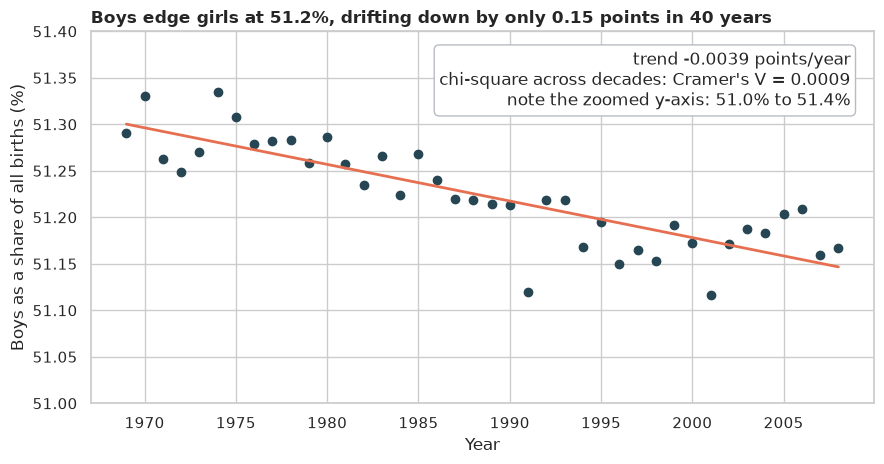

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(share_by_year.index, share_by_year.to_numpy() * 100, "o", color=NAVY)
fitted = share_fit.intercept + share_fit.slope * share_by_year.index.to_numpy()
ax.plot(share_by_year.index, fitted * 100, color=ORANGE, lw=2)
ax.set_ylim(51.0, 51.4)
ax.set_xlabel("Year")
ax.set_ylabel("Boys as a share of all births (%)")
ax.text(0.97, 0.95,
        f"trend {share_fit.slope * 100:+.4f} points/year\n"
        f"chi-square across decades: Cramer's V = {cramers_v:.4f}\n"
        "note the zoomed y-axis: 51.0% to 51.4%",
        transform=ax.transAxes, ha="right", va="top",
        bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
ax.set_title(f"Boys edge girls at {male_share:.1%}, drifting down by only "
             f"{abs(change) * 100:.2f} points in 40 years", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "05_sex_ratio.png", dpi=150)
plt.show()

**How to read this.**

- **Is it 50/50? No, and that is very well measured.** About **51.2% of births are boys** (roughly 105 boys per 100 girls). The z-statistic is about 300, so the p-value is below floating-point precision; the 95% CI is roughly ±0.008 percentage points. We **reject H₀**. It is a small gap (1.2 percentage points above 50%), but it is rock-solid.
- **Is it stable across decades? Statistically no, practically yes.** The chi-square test rejects equality (p ≈ 5e-27), but **Cramér's V is only about 0.0009**, essentially zero. The slope is about **−0.004 percentage points per year**, with a CI excluding 0, so the boy share has drifted down by roughly **0.15 points over the period** (fitted trend; 51.29% in 1969 against 51.17% in 2008).
- **This is the "huge sample" trap in action.** A p-value of 1e-27 sounds dramatic, but the actual change is about a tenth of a percentage point. The effect size, not the p-value, tells us this is a footnote, not a trend anyone would notice.

## 9. Forecasting honestly

*What:* can we forecast the number of births on **any given day of next year**? *Why it is a good test:* if our statistical findings are real, a model that knows about weekdays, months and holidays should forecast well. We build a ladder:

1. **Seasonal naive**, the baseline: predict the births on the *same weekday 364 days earlier*. It needs no model at all.
2. **Ridge regression** on calendar features: weekday, month, the eight holidays and Friday the 13th. It predicts a day's births *relative to its year's average*; we then multiply by **last year's average level**, which is the only thing we know about the level of next year.
3. **Gradient boosting** on the same features plus day-of-year (it can learn interactions, such as "holiday × weekday").
4. **Gradient boosting with an "oracle" level** (diagnostic only, never usable in practice): it is given the *true* average level of the year being predicted. This shows how much error comes from not knowing the level.

**How we avoid cheating (leakage).** Random train/test splits would be wrong for a time series: training on 1987 to predict 1985 is using the future. Instead we use **rolling-origin evaluation**: for each test year from 1984 to 1988, train *only on earlier years*, then predict that whole year. Features are calendar facts known in advance, so nothing leaks. The score is the **mean absolute error (MAE)**, the typical miss in births per day (about 10,400 on an average day in the test years).

**How we compare models.** There are only five test years, so a standard t-test across folds would be flimsy. Instead we pool all 1,827 test days and run a **block bootstrap**: re-draw whole *months* with replacement (days within a month are correlated, so resampling single days would make our CI too narrow), and compute the 95% CI for the difference in MAE.

In [15]:
def calendar_features(index: pd.DatetimeIndex, with_day_of_year: bool) -> pd.DataFrame:
    """Builds calendar-only features that are known long before the day arrives.

    Args:
        index: Dates to describe.
        with_day_of_year: Whether to add the day of the year (for tree models).

    Returns:
        Feature table with weekday and month dummies, holiday flags and Friday the 13th.
    """
    features = pd.get_dummies(pd.Series(index.dayofweek, index=index), prefix="dow").astype(float)
    months = pd.get_dummies(pd.Series(index.month, index=index), prefix="m").astype(float)
    features = features.join(months)
    for name, days in HOLIDAY_DATES.items():
        features[f"hol_{name}"] = index.isin(days).astype(float)
    features["fri13"] = ((index.day == 13) & (index.dayofweek == 4)).astype(float)
    if with_day_of_year:
        features["doy"] = index.dayofyear.astype(float)
    return features


def block_bootstrap_diff(
    err_a: pd.Series, err_b: pd.Series, rng: np.random.Generator
) -> tuple[float, float, float]:
    """Bootstraps the mean difference of two error series, resampling whole months.

    Args:
        err_a: Absolute errors of model A, indexed by date.
        err_b: Absolute errors of model B, indexed by the same dates.
        rng: Random generator.

    Returns:
        Mean difference (A minus B), CI lower bound, CI upper bound.
    """
    diff = err_a - err_b
    blocks = diff.groupby(diff.index.to_period("M")).agg(["sum", "count"])
    picks = rng.integers(0, len(blocks), (N_BOOTSTRAP, len(blocks)))
    sums = blocks["sum"].to_numpy()[picks].sum(axis=1)
    counts = blocks["count"].to_numpy()[picks].sum(axis=1)
    boot = sums / counts
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(diff.mean()), float(lo), float(hi)


NOT_HOLIDAYS = ("Leap day (Feb 29)", "Friday the 13th")
HOLIDAY_DATES = {k: v for k, v in specials.items() if k not in NOT_HOLIDAYS}
yearly_level = daily.groupby(daily.index.year).mean()
relative = daily / daily.index.year.map(yearly_level).to_numpy()

predictions = []
for test_year in TEST_YEARS:
    train_days = daily.index[daily.index.year < test_year]
    test_days = daily.index[daily.index.year == test_year]
    last_level = yearly_level[test_year - 1]
    oracle_level = yearly_level[test_year]

    ridge = Ridge(alpha=1.0).fit(calendar_features(train_days, False), relative[train_days])
    ridge_rel = ridge.predict(calendar_features(test_days, False))
    boost = GradientBoostingRegressor(
        max_depth=3, n_estimators=300, learning_rate=0.05, subsample=0.8, random_state=SEED
    ).fit(calendar_features(train_days, True), relative[train_days])
    boost_rel = boost.predict(calendar_features(test_days, True))

    predictions.append(pd.DataFrame({
        "actual": daily[test_days],
        "Seasonal naive (364 days ago)": daily.shift(364)[test_days],
        "Ridge (calendar x last level)": ridge_rel * last_level,
        "Boosting (calendar x last level)": boost_rel * last_level,
        "Boosting + oracle level (cheating)": boost_rel * oracle_level,
    }, index=test_days))

predictions = pd.concat(predictions)
models = [c for c in predictions.columns if c != "actual"]
abs_err = predictions[models].sub(predictions["actual"], axis=0).abs()

mae_by_year = abs_err.groupby(abs_err.index.year).mean().T
mae_by_year["mean"] = mae_by_year.mean(axis=1)
mae_by_year.round(0).astype(int)

date,1984,1985,1986,1987,1988,mean
Seasonal naive (364 days ago),327,373,239,287,371,319
Ridge (calendar x last level),294,396,341,396,444,374
Boosting (calendar x last level),267,380,317,386,432,356
Boosting + oracle level (cheating),262,276,318,346,349,310


In [16]:
rng = np.random.default_rng(SEED)
reference = "Seasonal naive (364 days ago)"
rows = {}
for name in models:
    if name == reference:
        continue
    diff, lo, hi = block_bootstrap_diff(abs_err[name], abs_err[reference], rng)
    rows[f"{name} minus naive"] = {"MAE difference": diff, "CI low": lo, "CI high": hi}
oracle_gain = block_bootstrap_diff(
    abs_err["Boosting + oracle level (cheating)"], abs_err["Boosting (calendar x last level)"], rng
)
rows["Oracle level minus last level (both boosting)"] = dict(
    zip(["MAE difference", "CI low", "CI high"], oracle_gain, strict=True)
)
mean_actual = predictions["actual"].mean()
poisson_floor = 0.798 * np.sqrt(mean_actual)
print(f"Test days: {len(predictions):,}; mean actual births/day: {mean_actual:,.0f}")
print(f"Rough floor if births were pure random counts (Poisson): MAE about {poisson_floor:.0f}")
pd.DataFrame(rows).T.round(0).astype(int)

Test days: 1,827; mean actual births/day: 10,359
Rough floor if births were pure random counts (Poisson): MAE about 81


,MAE difference,CI low,CI high
Ridge (calendar x last level) minus naive,55,27,85
Boosting (calendar x last level) minus naive,37,4,69
Boosting + oracle level (cheating) minus naive,-9,-41,21
Oracle level minus last level (both boosting),-46,-61,-32


**How to read this.** (MAE is the typical miss in births per day; lower is better.)

- **The naive baseline is very hard to beat:** about **319** births a day off (about 3% of a day's births). It automatically inherits last year's level, weekday pattern, season, and most holidays.
- **Ridge on calendar features does worse** (about 374, which is **55 births a day worse** than naive; 95% CI 27 to 85) and **gradient boosting** is in between (about 356, **37 worse**; CI 4 to 69, only just distinguishable from no difference). Neither calendar model beats the baseline.
- **Why? The yearly level, not the calendar.** Look at the "oracle" row: if we *were told the true average level of the year* (impossible in practice), gradient boosting drops to about **310**, matching the naive baseline (difference −9, CI −41 to +21). The calendar knowledge is real, but the **year-to-year level of births moves by −1% to +3%** (compare the line chart of annual births), and that uncertainty alone costs about **46 births a day** of error (the oracle-minus-last-level row, CI −61 to −32).
- **There is also a hard floor.** Even a perfect model cannot predict a *count* exactly: if births were pure random events at about 10,400 a day (the average in the test years), the typical miss would still be about 81. Our best models are about four times that, so there is real room left, but not an unlimited amount.

The lesson is the "data storytelling over model churn" point: the weekday, season and holiday effects are **statistically overwhelming**, yet turning them into a better forecast than "same day last year" needs a better way to predict the *level*, not a fancier calendar model.

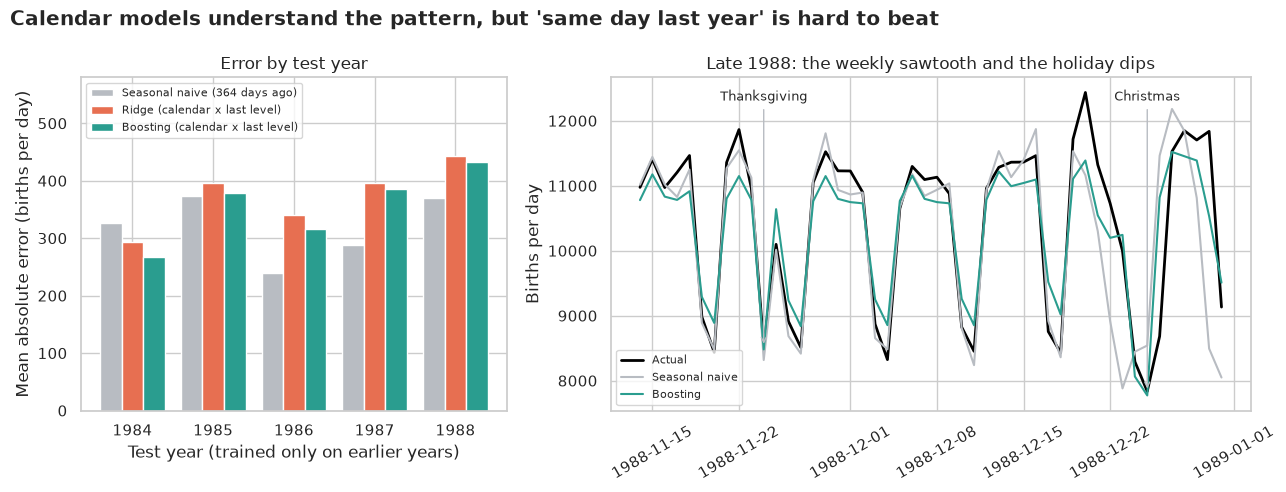

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.5]})

plot_models = models[:-1]
x = np.arange(len(TEST_YEARS))
width = 0.8 / len(plot_models)
palette = [GREY, ORANGE, TEAL]
for i, name in enumerate(plot_models):
    axes[0].bar(x + i * width, mae_by_year.loc[name, list(TEST_YEARS)], width, label=name,
                color=palette[i])
axes[0].set_xticks(x + width, [str(y) for y in TEST_YEARS])
axes[0].set_ylabel("Mean absolute error (births per day)")
axes[0].set_xlabel("Test year (trained only on earlier years)")
axes[0].set_ylim(0, 580)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Error by test year")

window = predictions.loc["1988-11-14":"1988-12-31"]
axes[1].plot(window.index, window["actual"], color="black", lw=2, label="Actual")
axes[1].plot(window.index, window[models[0]], color=GREY, lw=1.5, label="Seasonal naive")
axes[1].plot(window.index, window[models[2]], color=TEAL, lw=1.5, label="Boosting")
for day, label in ((pd.Timestamp("1988-11-24"), "Thanksgiving"),
                   (pd.Timestamp("1988-12-25"), "Christmas")):
    axes[1].annotate(label, (day, window.loc[day, "actual"]),
                     (day, window["actual"].max() * 0.99), ha="center", fontsize=9,
                     arrowprops={"arrowstyle": "->", "color": GREY})
axes[1].set_ylabel("Births per day")
axes[1].legend(fontsize=8, loc="lower left")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("Late 1988: the weekly sawtooth and the holiday dips")

fig.suptitle("Calendar models understand the pattern, but 'same day last year' is hard to beat",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "06_forecast.png", dpi=150)
plt.show()

**How to read this.** Left: the naive baseline (grey) has the lowest or near-lowest error in most test years, with boosting (teal) competitive in some. Right: the last seven weeks of 1988. The real births (black) show the **weekly sawtooth** (weekends dip) and sharp **holiday notches** on Thanksgiving and Christmas. Boosting follows the same shape, because it learned those effects from calendar features; the naive forecast catches the weekly rhythm but misplaces holidays that fall on different weekdays from year to year.

## 10. 🎯 Takeaways

1. **Babies follow the business calendar.** Across 1,042 weeks, weekend days had about **84.5%** of a weekday's births (CI 84.3% to 84.7%), lower in every single week.
2. **The weekend dip is deepening**, from 12% (1969) to 21% (1988), about 0.44 percentage points a year (Spearman ρ ≈ −0.98). This fits the "more scheduled births" idea, but the data cannot confirm the cause.
3. **September is the busiest month (+6%) and January the quietest (−4%)** (Kruskal-Wallis ε² ≈ 0.72, a very large effect).
4. **Major holidays cut births by 14% to 20%**, and **Friday the 13th by about 3%**. Leap day showed no detectable effect, but with only 5 observations the test cannot say.
5. **About 51.2% of births are boys**, and the share drifts down by only about 0.15 points over 40 years. The p-values are tiny (1e-27) but Cramér's V ≈ 0.0009: **statistically significant, practically trivial**.
6. **A calendar model did not beat "same day last year".** Even with a perfect yearly level, it only matched the baseline. The limiting factor is the year-to-year level of births, not the calendar.

## 11. ⚠️ Limitations and edge cases

- **Two data eras.** Daily analysis covers only 1969-1988. Weekday and holiday patterns could be different in the 1990s and 2000s, when induction and C-section rates changed further, and we cannot check with monthly totals.
- **Associations, not causes.** The data does not say which births were induced or scheduled, so the "bakery" explanation is a hypothesis that fits, not a measured fact.
- **Impossible dates removed.** About 0.01% of daily-era births (457 rows) had impossible dates and are left out of the daily analysis; they are kept in the monthly totals.
- **The baseline for special days is a choice.** Using the median of the six surrounding same-weekday observations can be biased where holidays cluster (late December, early January). The qualitative result is robust, the exact percentages are not.
- **Small n for rare days.** Leap day has only 5 observations, and Friday the 13th 34. Holm corrects for the 10 special days we picked, not for every date one could examine.
- **Pooled sex ratio.** The sex-ratio test uses 152 million births pooled across the whole country and decades, so it says nothing about any one hospital or region.
- **A simple forecaster.** The forecasting ladder does not model the yearly level beyond "last year's average", does not use any outside information (such as the number of women of childbearing age), and was evaluated on only five test years.
- **Autocorrelation.** Neighbouring days are correlated; the weekly pairing and month-block bootstrap reduce but do not eliminate that.

---
*Run `uv run jupyter nbconvert --to html --execute ML/birth-rate-analysis/birth_rate_analysis.ipynb --output-dir docs --output ml-birth-rate-analysis` to rebuild the web version (`docs/ml-birth-rate-analysis.html`).*